In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

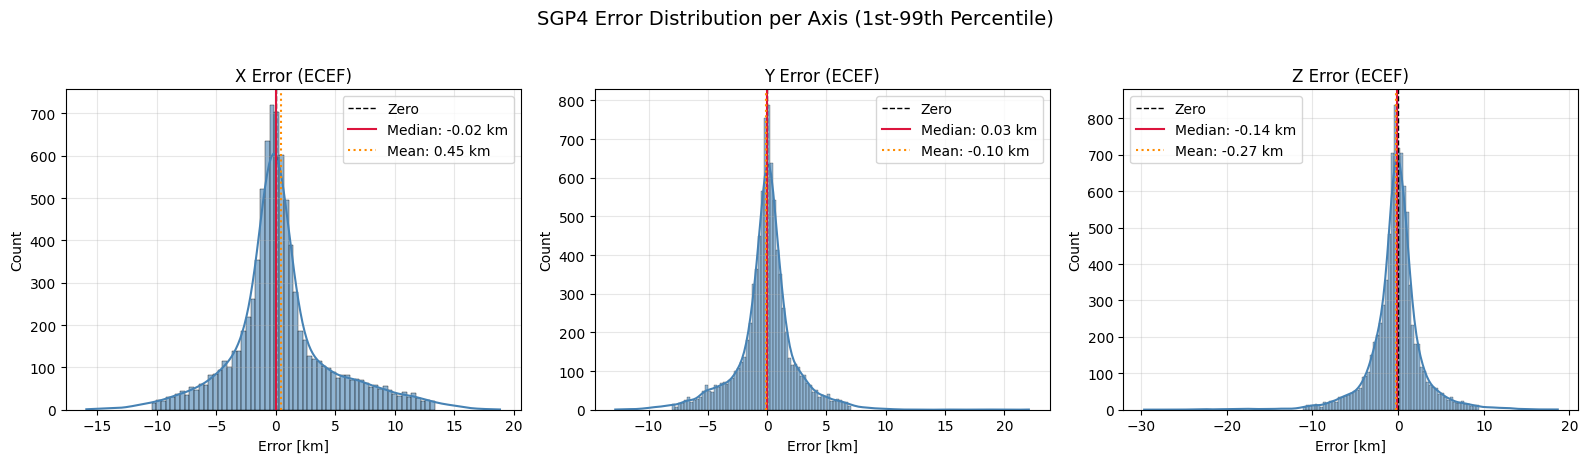

In [27]:
df = pd.read_csv("cleaned_final.csv")

axes_col = ['x_error', 'y_error', 'z_error']
titles = ['X Error (ECEF)', 'Y Error (ECEF)', 'Z Error (ECEF)']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col, title in zip(axes, axes_col, titles):
    data = df[col].dropna()
    
    # Clip x-axis to 1st–99th percentile so extreme outliers (like 300–500 km jumps)
    # don't squash the main distribution into a single thin spike
    low, high = np.percentile(data, [1, 99])
    
    sns.histplot(data, bins=60, binrange=(low, high), kde=True, ax=ax,
                 color='steelblue', alpha=0.6)
    
    med = np.median(data)
    mean = np.mean(data)
    
    ax.axvline(0, color='black', linestyle='--', linewidth=1, label='Zero')
    ax.axvline(med, color='crimson', linestyle='-', linewidth=1.5, label=f'Median: {med:.2f} km')
    ax.axvline(mean, color='darkorange', linestyle=':', linewidth=1.5, label=f'Mean: {mean:.2f} km')
    
    ax.set_title(title)
    ax.set_xlabel('Error [km]')
    ax.set_ylabel('Count')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('SGP4 Error Distribution per Axis (1st-99th Percentile)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

3D Error >  10 km: 1016 rows (11.54%)
3D Error >  50 km:    0 rows (0.00%)
3D Error > 100 km:    0 rows (0.00%)
3D Error > 500 km:    0 rows (0.00%)


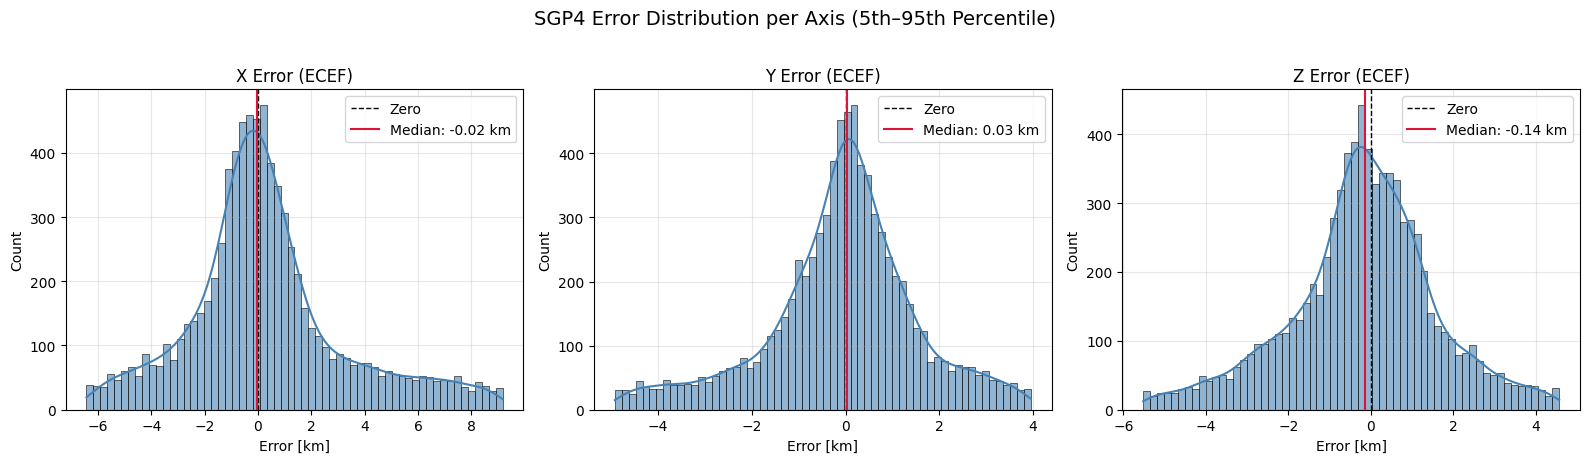

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Check how many rows are extreme outliers (e.g. maneuvers / bad TLEs)
err3d = np.linalg.norm(df[['x_error', 'y_error', 'z_error']].values, axis=1)
for thresh in [10, 50, 100, 500]:
    pct = (err3d > thresh).mean() * 100
    print(f"3D Error > {thresh:3d} km: {(err3d > thresh).sum():4d} rows ({pct:.2f}%)")

# 2. Plot with properly clipped data (5th–95th percentile)
axes_cols = ['x_error', 'y_error', 'z_error']
titles = ['X Error (ECEF)', 'Y Error (ECEF)', 'Z Error (ECEF)']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col, title in zip(axes, axes_cols, titles):
    data = df[col].dropna()
    low, high = np.percentile(data, [5, 95])
    clipped = data[(data >= low) & (data <= high)]
    
    sns.histplot(clipped, bins=60, kde=True, ax=ax, color='steelblue', alpha=0.6)
    
    med = np.median(data)
    ax.axvline(0, color='black', linestyle='--', linewidth=1, label='Zero')
    ax.axvline(med, color='crimson', linestyle='-', linewidth=1.5, label=f'Median: {med:.2f} km')
    
    ax.set_title(title)
    ax.set_xlabel('Error [km]')
    ax.set_ylabel('Count')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('SGP4 Error Distribution per Axis (5th–95th Percentile)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()